<a href="https://colab.research.google.com/github/julienessan/Gomycode_Cours_Data_Sciences/blob/main/Checkpoint_Batch%20Normalization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Checkpoint : Entraîner un CNN avec normalisation par lot (Batch Normalization)

# Objectif
Intégrer la normalisation par lot (Batch Normalization) dans un réseau de neurones convolutionnel et observer son impact sur la stabilité et la convergence de l’entraînement.

## 1. Imports et chargement des données

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)

(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

# normalisation des pixels entre 0 et 1
x_train = x_train / 255.0
x_test = x_test / 255.0

noms = ["avion", "voiture", "oiseau", "chat", "cerf",
        "chien", "grenouille", "cheval", "bateau", "camion"]

print("Train :", x_train.shape, "| Test :", x_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2189s 13us/step
Train : (50000, 32, 32, 3) | Test : (10000, 32, 32, 3)


## 2. Hyperparamètres communs

Je les définis une seule fois. Les deux modèles utilisent ainsi exactement les mêmes valeurs.


In [14]:
EPOQUES = 20
BATCH = 64
TAUX_APPRENTISSAGE = 0.01

## 3. Construction des deux modèles

J'écris une seule fonction avec un paramètre `avec_bn`. Les deux modèles ont ainsi la même architecture, et la seule différence est la présence de la BN.

Chaque bloc convolutionnel contient :
- **sans BN** : `Conv2D` (ReLU) → `MaxPooling`
- **avec BN** : `Conv2D` → `BatchNormalization` → ReLU → `MaxPooling`

In [15]:
def construire_cnn(avec_bn):
    keras.utils.set_random_seed(42)
    model = keras.Sequential()
    model.add(keras.Input(shape=(32, 32, 3)))

    for filtres in [32, 64, 128]:          # 3 blocs convolutionnels
        if avec_bn:
            model.add(layers.Conv2D(filtres, 3, padding="same"))
            model.add(layers.BatchNormalization())
            model.add(layers.Activation("relu"))
        else:
            model.add(layers.Conv2D(filtres, 3, padding="same", activation="relu"))
        model.add(layers.MaxPooling2D())

    model.add(layers.Flatten())
    model.add(layers.Dense(128, activation="relu"))
    model.add(layers.Dense(10, activation="softmax"))

    model.compile(optimizer=keras.optimizers.Adam(learning_rate=TAUX_APPRENTISSAGE),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

baseline = construire_cnn(avec_bn=False)
bn_cnn = construire_cnn(avec_bn=True)

baseline.summary()
bn_cnn.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 356,810 (1.36 MB)

 Trainable params: 356,810 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_11 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 357,706 (1.36 MB)

 Trainable params: 357,258 (1.36 MB)

 Non-trainable params: 448 (1.75 KB)

## 4. Entraînement des deux modèles

In [16]:
print("=== Modèle A : baseline ===")
hist_a = baseline.fit(x_train, y_train, epochs=EPOQUES, batch_size=BATCH,
                      validation_data=(x_test, y_test))

=== Modèle A : baseline ===
Epoch 1/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.0975 - loss: 2.3052 - val_accuracy: 0.1000 - val_loss: 2.3038
Epoch 2/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.0980 - loss: 2.3036 - val_accuracy: 0.1000 - val_loss: 2.3038
Epoch 3/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.0980 - loss: 2.3036 - val_accuracy: 0.1000 - val_loss: 2.3038
Epoch 4/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.0980 - loss: 2.3036 - val_accuracy: 0.1000 - val_loss: 2.3038
Epoch 5/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.0980 - loss: 2.3036 - val_accuracy: 0.1000 - val_loss: 2.3038
Epoch 6/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.0980 - loss: 2.3036 - val_accuracy: 0.1000 - val_loss: 2.3038
Epoch 7/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.0980 - loss: 2.3036 - val_accuracy: 0.1000 - val_loss: 2.3038
Epoch 8/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.0980 - los

In [17]:
print("=== Modèle B : BN-CNN ===")
hist_b = bn_cnn.fit(x_train, y_train, epochs=EPOQUES, batch_size=BATCH,
                    validation_data=(x_test, y_test))

=== Modèle B : BN-CNN ===
Epoch 1/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 13s 11ms/step - accuracy: 0.3028 - loss: 2.0707 - val_accuracy: 0.3224 - val_loss: 2.0470
Epoch 2/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.5394 - loss: 1.2445 - val_accuracy: 0.4872 - val_loss: 1.4402
Epoch 3/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.6317 - loss: 1.0267 - val_accuracy: 0.5633 - val_loss: 1.2669
Epoch 4/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.6820 - loss: 0.8982 - val_accuracy: 0.5054 - val_loss: 1.7207
Epoch 5/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7171 - loss: 0.8078 - val_accuracy: 0.5383 - val_loss: 1.6006
Epoch 6/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7412 - loss: 0.7406 - val_accuracy: 0.5073 - val_loss: 1.8530
Epoch 7/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.7618 - loss: 0.6777 - val_accuracy: 0.5795 - val_loss: 1.4585
Epoch 8/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7800 - los

## 5. Comparaison des courbes

Les traits pleins représentent l'entraînement, les pointillés la validation.

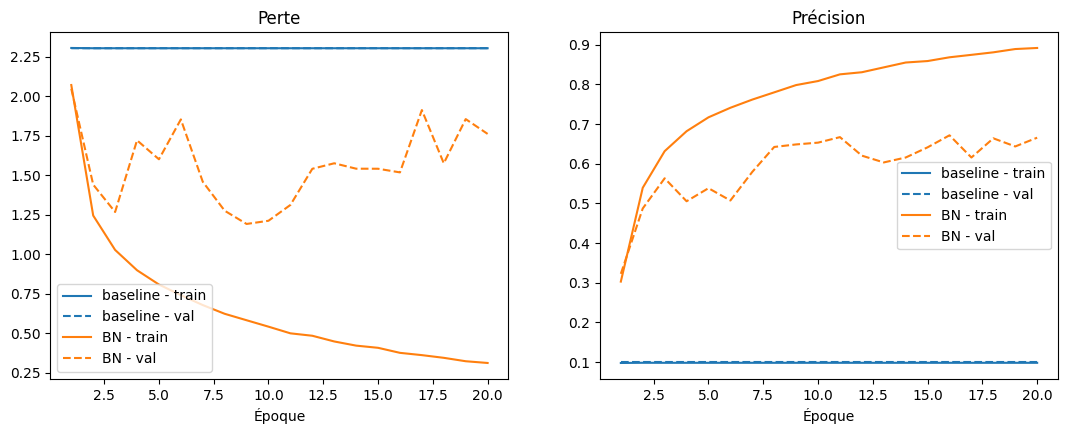

In [18]:
a, b = hist_a.history, hist_b.history
ep = range(1, EPOQUES + 1)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].plot(ep, a["loss"], color="tab:blue", label="baseline - train")
ax[0].plot(ep, a["val_loss"], color="tab:blue", linestyle="--", label="baseline - val")
ax[0].plot(ep, b["loss"], color="tab:orange", label="BN - train")
ax[0].plot(ep, b["val_loss"], color="tab:orange", linestyle="--", label="BN - val")
ax[0].set_title("Perte"); ax[0].set_xlabel("Époque"); ax[0].legend()

ax[1].plot(ep, a["accuracy"], color="tab:blue", label="baseline - train")
ax[1].plot(ep, a["val_accuracy"], color="tab:blue", linestyle="--", label="baseline - val")
ax[1].plot(ep, b["accuracy"], color="tab:orange", label="BN - train")
ax[1].plot(ep, b["val_accuracy"], color="tab:orange", linestyle="--", label="BN - val")
ax[1].set_title("Précision"); ax[1].set_xlabel("Époque"); ax[1].legend()

plt.show()

### Perte et précision par époque

In [19]:
def premiere_epoque(h, seuil=0.60):
    for i, acc in enumerate(h["val_accuracy"]):
        if acc >= seuil:
            return i + 1
    return "jamais"

def instabilite(h):
    return np.mean(np.abs(np.diff(h["val_loss"])))

print(f"{'':<34}{'baseline':>10}{'BN-CNN':>10}")
print(f"{'1re époque à 60 % (val)':<34}{str(premiere_epoque(a)):>10}{str(premiere_epoque(b)):>10}")
print(f"{'Variation moyenne de val_loss':<34}{instabilite(a):>10.4f}{instabilite(b):>10.4f}")
print(f"{'Précision val à l époque 5':<34}{a['val_accuracy'][4]:>10.2%}{b['val_accuracy'][4]:>10.2%}")
print(f"{'Précision val finale':<34}{a['val_accuracy'][-1]:>10.2%}{b['val_accuracy'][-1]:>10.2%}")
print(f"{'Meilleure précision val':<34}{max(a['val_accuracy']):>10.2%}{max(b['val_accuracy']):>10.2%}")
print(f"{'Écart train - val (fin)':<34}{a['accuracy'][-1] - a['val_accuracy'][-1]:>10.2%}{b['accuracy'][-1] - b['val_accuracy'][-1]:>10.2%}")

                                    baseline    BN-CNN
1re époque à 60 % (val)               jamais         8
Variation moyenne de val_loss         0.0000    0.2008
Précision val à l époque 5            10.00%    53.83%
Précision val finale                  10.00%    66.57%
Meilleure précision val               10.00%    67.17%
Écart train - val (fin)               -0.20%    22.63%


## 5. Courte analyse

L’apport de la BN dépend des réglages. Avec un taux d’apprentissage déjà bien choisi et un réseau peu profond, elle ne change presque rien. Elle devient décisive quand l’entraînement est fragile : avec un taux d’apprentissage élevé, elle fait la différence entre un modèle qui apprend et un modèle qui reste bloqué.